# C02 — Caps, swaptions, cubo de volatilidad y SABR

**Objetivos:** extraer volatilidades de caplet a partir de volatilidades planas de cap; leer la matriz de
swaptions; calibrar SABR a un *smile*; medir cuánto cambia el precio de una opción fuera del dinero frente a
usar la volatilidad ATM; caso de la aseguradora.

**Fuentes:** Hull cap. 29; Veronesi cap. 20 (20.1.1–20.1.3 sobre volatilidades planas y forward). SABR: Hagan et
al. (2002), *Managing Smile Risk*. Datos sintéticos.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # notebooks/ -> repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

from derivlab.market import sample_market
from derivlab.curves import build_curves, discount_t
from derivlab.dates import spot_date, add_months
from derivlab.scenarios import HullWhite
from derivlab.rate_options import (bachelier, bachelier_vega, sabr_normal_vol, calibrate_sabr, strip_caplet_vols,
                                   forward_swap, cap_value)
from derivlab.short_rate import forward_swap_today
from derivlab.vol_market import (SWAPTION_EXPIRIES, SWAPTION_TENORS, SWAPTION_ATM_NORMAL_VOLS, CAP_MATURITIES,
                                 CAP_FLAT_NORMAL_VOLS, SMILE_5Y10Y_OFFSETS_BP, SMILE_5Y10Y_NORMAL_VOLS)

m = sample_market()
estr, eur = build_curves(m)
ref, spot = m["ref_date"], spot_date(m["ref_date"])
hw = HullWhite(estr, eur)

## 1. De volatilidades planas de cap a volatilidades de caplet

El mercado cotiza cada cap con una sola volatilidad (plana) para todos sus caplets. Pero el cap a 3 años y el
cap a 2 años comparten los caplets de los dos primeros años, así que la volatilidad propia de los caplets entre
2 y 3 años se puede despejar (Veronesi 20.1.2): *stripping*.

 cap_years atm_strike flat_vol_bp caplet_vol_bp
         1     2.074%        62.0          62.0
         2     2.151%        74.0          77.7
         3     2.241%        80.0          85.8
         4     2.326%        83.0          87.7
         5     2.404%        84.0          84.3
         7     2.537%        84.0          83.4
        10     2.685%        82.0          78.8
CASE flat cap vols rise from 62 to 84 bp; stripped caplet vols peak at 87.7 bp for caplets fixing before year 4


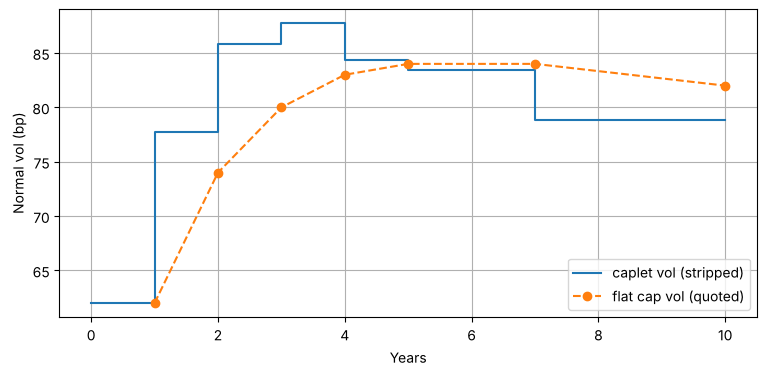

In [2]:
atm_k = [forward_swap(estr, eur, spot, y)[0] for y in CAP_MATURITIES]
vol_fn, knots = strip_caplet_vols(ref, estr, eur, spot, CAP_MATURITIES, CAP_FLAT_NORMAL_VOLS, atm_k)
strip = pd.DataFrame({"cap_years": CAP_MATURITIES, "atm_strike": atm_k, "flat_vol_bp": np.array(CAP_FLAT_NORMAL_VOLS) * 1e4,
                      "caplet_vol_bp": [v * 1e4 for _, v in knots]})
print(strip.to_string(index=False, formatters={"atm_strike": "{:.3%}".format, "flat_vol_bp": "{:.1f}".format,
                                               "caplet_vol_bp": "{:.1f}".format}))
peak = strip.loc[strip.caplet_vol_bp.idxmax()]
print(f"CASE flat cap vols rise from {strip.flat_vol_bp.iloc[0]:.0f} to {strip.flat_vol_bp.max():.0f} bp; "
      f"stripped caplet vols peak at {peak.caplet_vol_bp:.1f} bp for caplets fixing before year {int(peak.cap_years)}")
tt = np.linspace(0.3, 9.8, 200)
plt.step([0] + CAP_MATURITIES, [knots[0][1] * 1e4] + [v * 1e4 for _, v in knots], where="pre", label="caplet vol (stripped)")
plt.plot(CAP_MATURITIES, strip.flat_vol_bp, "o--", label="flat cap vol (quoted)")
plt.xlabel("Years"); plt.ylabel("Normal vol (bp)"); plt.legend(); plt.show()

La volatilidad plana es una media de las de sus caplets: se mueve más despacio y esconde la joroba. Por eso un cap
de 3 a 5 años (*forward cap*) no se puede valorar con la volatilidad plana del cap a 5 años.

## 2. La matriz de swaptions ATM

ATM normal vols (bp), rows = option expiry, columns = swap tenor
     1y  2y  5y  10y  20y
1y   78  80  82   80   75
2y   82  83  84   81   76
3y   84  84  84   81   76
5y   83  83  82   79   74
7y   80  80  79   76   72
10y  76  76  75   72   68


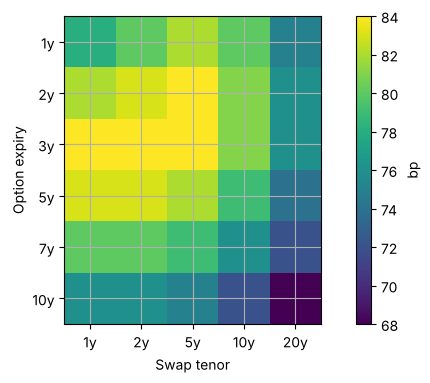

In [3]:
mat = pd.DataFrame(SWAPTION_ATM_NORMAL_VOLS * 1e4, index=[f"{e}y" for e in SWAPTION_EXPIRIES],
                   columns=[f"{t}y" for t in SWAPTION_TENORS])
print("ATM normal vols (bp), rows = option expiry, columns = swap tenor")
print(mat.round(0).astype(int))
plt.imshow(mat.values, cmap="viridis"); plt.colorbar(label="bp")
plt.xticks(range(len(SWAPTION_TENORS)), mat.columns); plt.yticks(range(len(SWAPTION_EXPIRIES)), mat.index)
plt.xlabel("Swap tenor"); plt.ylabel("Option expiry"); plt.show()

Dos rasgos típicos: una joroba en los vencimientos de 2 a 3 años y volatilidades más bajas en los swaps largos,
porque los tipos largos se mueven menos que los cortos. El cubo completo añade una tercera dimensión: el strike.

## 3. SABR en el *smile* de la 5y10y

SABR modela el forward F y su volatilidad α como dos procesos correlacionados:

$$dF = \alpha F^{\beta} dW_1, \qquad d\alpha = \nu\,\alpha\, dW_2, \qquad dW_1 dW_2 = \rho\, dt$$

- **α** fija el nivel de la volatilidad; **ρ** inclina el *smile* (negativo: más vol en strikes bajos);
  **ν** (vol de la vol) curva las alas; **β** fija cómo se mueve la volatilidad con el nivel del tipo.
- Con β = 0 (SABR normal) admite tipos negativos sin desplazamiento. Con β = 0,5 se usa un desplazamiento.

5y10y forward swap 3.098%
               alpha  beta     rho      nu  shift  rmse_bp
normal SABR   0.0076   0.0 -0.1980  0.3026   0.00   0.1954
shifted SABR  0.0343   0.5 -0.4192  0.3577   0.02   0.3332
 offset_bp  market_bp  err_beta0_bp  err_beta05_bp
      -200       91.0          0.04          -0.34
      -100       84.0         -0.15           0.19
       -50       81.1         -0.05           0.23
       -25       79.5          0.43           0.61
         0       79.3         -0.26          -0.22
        25       78.5         -0.11          -0.23
        50       77.8          0.19          -0.05
       100       78.1         -0.11          -0.48
       200       80.8          0.02           0.29
CASE SABR beta=0: alpha 0.00763, rho -0.20, nu 0.30, RMSE 0.20 bp; beta=0.5 shifted: RMSE 0.33 bp


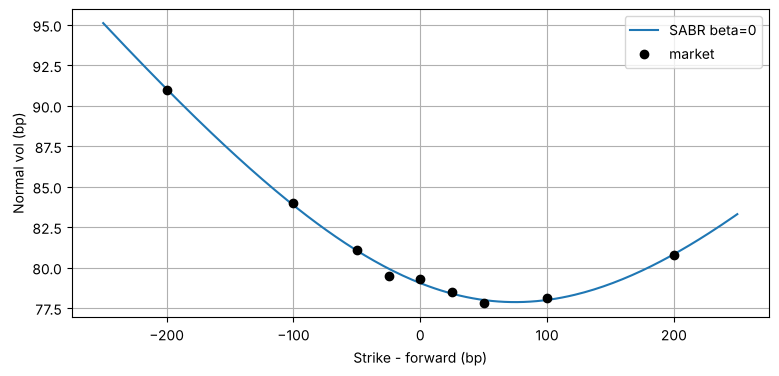

In [4]:
F, A = forward_swap_today(hw, 5, 10)
ks = F + np.array(SMILE_5Y10Y_OFFSETS_BP) * 1e-4
vols = np.array(SMILE_5Y10Y_NORMAL_VOLS)
fit0 = calibrate_sabr(F, 5.0, ks, vols, beta=0.0)
fit5 = calibrate_sabr(F, 5.0, ks, vols, beta=0.5, shift=0.02)
params = pd.DataFrame([{k: fit0[k] for k in ["alpha", "beta", "rho", "nu", "shift", "rmse_bp"]},
                       {k: fit5[k] for k in ["alpha", "beta", "rho", "nu", "shift", "rmse_bp"]}], index=["normal SABR", "shifted SABR"])
print(f"5y10y forward swap {F:.3%}")
print(params.round(4))
res = pd.DataFrame({"offset_bp": SMILE_5Y10Y_OFFSETS_BP, "market_bp": vols * 1e4, "err_beta0_bp": fit0["errors_bp"],
                    "err_beta05_bp": fit5["errors_bp"]})
print(res.round(2).to_string(index=False))
print(f"CASE SABR beta=0: alpha {fit0['alpha']:.5f}, rho {fit0['rho']:.2f}, nu {fit0['nu']:.2f}, RMSE {fit0['rmse_bp']:.2f} bp; "
      f"beta=0.5 shifted: RMSE {fit5['rmse_bp']:.2f} bp")
kk = F + np.linspace(-0.025, 0.025, 200)
plt.plot((kk - F) * 1e4, sabr_normal_vol(F, kk, 5, fit0["alpha"], 0.0, fit0["rho"], fit0["nu"]) * 1e4, label="SABR beta=0")
plt.plot(np.array(SMILE_5Y10Y_OFFSETS_BP), vols * 1e4, "ko", label="market")
plt.xlabel("Strike - forward (bp)"); plt.ylabel("Normal vol (bp)"); plt.legend(); plt.show()

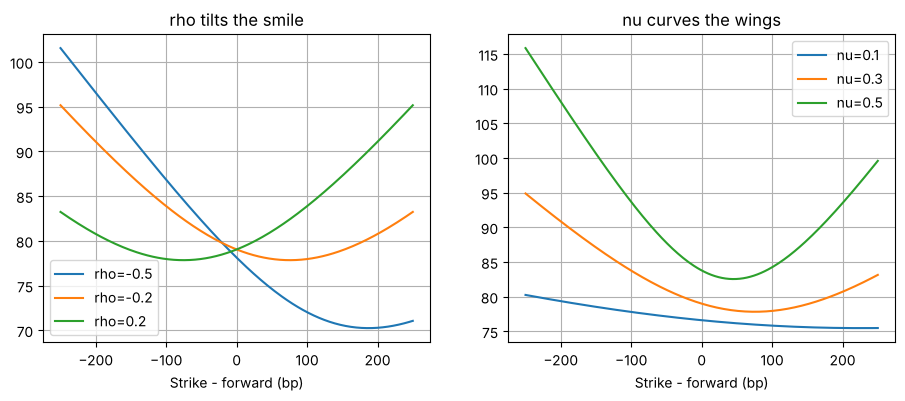

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for r in [-0.5, -0.2, 0.2]:
    ax[0].plot((kk - F) * 1e4, sabr_normal_vol(F, kk, 5, fit0["alpha"], 0.0, r, fit0["nu"]) * 1e4, label=f"rho={r}")
for n in [0.1, 0.3, 0.5]:
    ax[1].plot((kk - F) * 1e4, sabr_normal_vol(F, kk, 5, fit0["alpha"], 0.0, fit0["rho"], n) * 1e4, label=f"nu={n}")
ax[0].set_title("rho tilts the smile"); ax[1].set_title("nu curves the wings")
for a_ in ax:
    a_.set_xlabel("Strike - forward (bp)"); a_.legend()
plt.show()

## 4. Caso: una aseguradora compra receivers 5y10y fuera del dinero

Una aseguradora con rentabilidades garantizadas pierde si bajan los tipos largos. Compra una **receiver swaption
5y10y con strike 100 pb por debajo del forward** sobre 200 M€. ¿Cuánto cambia el precio si se usa la
volatilidad ATM en lugar de la del *smile*?

In [6]:
N = 200e6
K = F - 0.0100
v_atm = sabr_normal_vol(F, F, 5, fit0["alpha"], 0.0, fit0["rho"], fit0["nu"])
v_k = sabr_normal_vol(F, K, 5, fit0["alpha"], 0.0, fit0["rho"], fit0["nu"])
p_atm_vol = N * A * float(bachelier(F, K, 5.0, v_atm, call=False))
p_smile = N * A * float(bachelier(F, K, 5.0, v_k, call=False))
vega_k = N * A * float(bachelier_vega(F, K, 5.0, v_k)) * 1e-4
print(f"CASE receiver 5y10y, strike {K:.3%} on 200M: ATM vol {v_atm * 1e4:.1f} bp -> {p_atm_vol / 1e6:.2f} M EUR; "
      f"smile vol {v_k * 1e4:.1f} bp -> {p_smile / 1e6:.2f} M EUR; difference {(p_smile - p_atm_vol) / 1e6:.2f} M EUR "
      f"({(p_smile / p_atm_vol - 1):.0%})")
print(f"CASE vega of the option: {vega_k:,.0f} EUR per bp of vol")

CASE receiver 5y10y, strike 2.098% on 200M: ATM vol 79.0 bp -> 4.82 M EUR; smile vol 83.8 bp -> 5.38 M EUR; difference 0.56 M EUR (12%)
CASE vega of the option: 118,396 EUR per bp of vol


### Dinámica del *smile*: cuando se mueve el forward

Con β = 0 la volatilidad normal ATM apenas cambia si el forward sube; con β = 0,5 sube con él. Eso cambia la
delta que hay que cubrir: la delta con *smile* incluye ∂σ/∂F.

In [7]:
def price(fwd, beta_fit):
    f = fit0 if beta_fit == 0 else fit5
    v = sabr_normal_vol(fwd, K, 5, f["alpha"], f["beta"], f["rho"], f["nu"], f["shift"])
    return float(bachelier(fwd, K, 5.0, v, call=False))
h = 1e-4
rows = []
for b in [0, 0.5]:
    f = fit0 if b == 0 else fit5
    atm_up = sabr_normal_vol(F + 0.005, F + 0.005, 5, f["alpha"], f["beta"], f["rho"], f["nu"], f["shift"])
    atm_now = sabr_normal_vol(F, F, 5, f["alpha"], f["beta"], f["rho"], f["nu"], f["shift"])
    smile_delta = (price(F + h, b) - price(F - h, b)) / (2 * h)
    rows.append({"model": f"beta={b}", "ATM vol now (bp)": atm_now * 1e4, "ATM vol if F +50bp (bp)": atm_up * 1e4,
                 "smile delta": smile_delta})
v_fixed = sabr_normal_vol(F, K, 5, fit0["alpha"], 0.0, fit0["rho"], fit0["nu"])
bs_delta = (float(bachelier(F + h, K, 5, v_fixed, False)) - float(bachelier(F - h, K, 5, v_fixed, False))) / (2 * h)
dyn = pd.DataFrame(rows)
print(dyn.round(3).to_string(index=False))
print(f"CASE delta with vol held fixed {bs_delta:.3f}; smile delta beta=0 {dyn['smile delta'].iloc[0]:.3f}, "
      f"beta=0.5 {dyn['smile delta'].iloc[1]:.3f}")

   model  ATM vol now (bp)  ATM vol if F +50bp (bp)  smile delta
  beta=0            79.037                   79.037       -0.248
beta=0.5            79.075                   82.941       -0.186
CASE delta with vol held fixed -0.297; smile delta beta=0 -0.248, beta=0.5 -0.186


## 5. Comprobaciones

In [8]:
for y, fv, k in zip(CAP_MATURITIES, CAP_FLAT_NORMAL_VOLS, atm_k):
    end = add_months(spot, 12 * y)
    assert abs(cap_value(ref, estr, eur, spot, end, 1.0, k, vol_fn) / cap_value(ref, estr, eur, spot, end, 1.0, k, fv) - 1) < 1e-8
assert fit0["rmse_bp"] < 0.5 and fit0["rho"] < 0
assert v_k > v_atm and p_smile > p_atm_vol
assert abs(dyn["ATM vol if F +50bp (bp)"].iloc[0] - dyn["ATM vol now (bp)"].iloc[0]) < abs(
    dyn["ATM vol if F +50bp (bp)"].iloc[1] - dyn["ATM vol now (bp)"].iloc[1])
print("All checks passed")

All checks passed


## Ejercicios

1. **Básico.** Valora un *forward cap* de 3 a 5 años, ATM del cap a 5 años, con la volatilidad plana de 5 años y con las volatilidades de caplet. ¿Cuánto cambia?
2. **Intermedio.** Recalibra SABR con β = 0 fijando ρ = 0. ¿Cuánto empeora el ajuste y en qué strikes?
3. **Avanzado.** La aseguradora compra además una payer 5y10y 100 pb por encima del forward (un *strangle*). Valóralo con ATM y con *smile*.

## Soluciones

In [9]:
k5 = atm_k[CAP_MATURITIES.index(5)]
s3, e5 = add_months(spot, 36), add_months(spot, 60)
flat = cap_value(ref, estr, eur, s3, e5, 100e6, k5, CAP_FLAT_NORMAL_VOLS[CAP_MATURITIES.index(5)])
stripped = cap_value(ref, estr, eur, s3, e5, 100e6, k5, vol_fn)
print(f"Forward cap 3y-5y on 100M: flat vol {flat:,.0f} EUR, stripped vols {stripped:,.0f} EUR ({stripped / flat - 1:+.1%})")

Forward cap 3y-5y on 100M: flat vol 1,395,384 EUR, stripped vols 1,435,240 EUR (+2.9%)


In [10]:
from scipy.optimize import least_squares
r0 = least_squares(lambda p: (sabr_normal_vol(F, ks, 5, p[0], 0.0, 0.0, p[1]) - vols) * 1e4, [0.008, 0.3],
                   bounds=([1e-5, 1e-4], [1, 3]))
print(f"rho fixed at 0: RMSE {np.sqrt(np.mean(r0.fun ** 2)):.2f} bp; errors by strike (bp): {np.round(r0.fun, 1)}")
print("Without rho the model cannot tilt the smile: it misses the low strikes and the high strikes in opposite directions.")

rho fixed at 0: RMSE 2.90 bp; errors by strike (bp): [-5.1 -3.1 -1.6 -0.3 -0.3  0.7  1.7  2.8  5.1]
Without rho the model cannot tilt the smile: it misses the low strikes and the high strikes in opposite directions.


In [11]:
Kp = F + 0.0100
vp = sabr_normal_vol(F, Kp, 5, fit0["alpha"], 0.0, fit0["rho"], fit0["nu"])
strangle_atm = N * A * (float(bachelier(F, K, 5, v_atm, False)) + float(bachelier(F, Kp, 5, v_atm, True)))
strangle_smile = N * A * (float(bachelier(F, K, 5, v_k, False)) + float(bachelier(F, Kp, 5, vp, True)))
print(f"Strangle: ATM vol {strangle_atm / 1e6:.2f} M EUR, smile {strangle_smile / 1e6:.2f} M EUR")

Strangle: ATM vol 9.64 M EUR, smile 10.08 M EUR
